# Score plasma-cell programs in bulk RNA-seq

**Biology rationale.** An independent bulk cohort tests whether single-cell-derived plasma-cell programs reproduce clinically relevant response associations.

**Aim.** Apply GSVA to bulk expression data and compare program scores across clinical groups.

**Data input.** `featureCounts.gencode_v22_rename.txt`, `bulk_signature_coverage.tsv`, `bulk_signature_heatmap.png`



**Data outputs.** `plasma_cnmf_3_topgenes_withoutIG_k=13.csv`, `bulk_signature_scores.tsv`, `signature1_boxplot.pdf`, `signature1_boxplot_1114.pdf`

## Corrected local rerun — 25 October 2026

The original featureCounts command lists sequencing abbreviations in column order. Matching those abbreviations to the clinical workbook resolves HCY as **BulkAL4** (previously mislabeled BulkAL5) and YJ as **BulkAL5**. LGL is the original **VCD** column and is excluded as requested. All 60,483 gene rows and all retained count values are unchanged. The cohort now contains exactly BulkAL1–BulkAL12. See `sample_mapping_audit.csv`, `sample_metadata.csv`, and `audit/clinical_cross_checks.csv`.

Clinical response and t(11;14) assignments agree with Supplementary Table 3. BulkAL6 is recorded as “Not 11;14” in the clinical workbook and “NA” in Table 3; its non-t(11;14) classification follows the clinical workbook and the original notebook. Counts: Good n=9, Poor n=3; non-t(11;14) n=8, t(11;14) n=4.

The original Ensembl-to-symbol mapping procedure, summed duplicate symbols, log2(CPM+1), Gaussian GSVA with mx.diff=TRUE, and two-sided unpaired Wilcoxon tests are retained. Base R CSV/TSV I/O replaces unavailable readr; score exports now retain sample IDs. The documented matrixStats compatibility option allows legacy GSVA to use its existing names behavior. The notebook checks uniqueness and the expected cohort before analysis. Plot jitter uses a fixed random seed. Software versions and the actual gene mapping are exported for reproducibility.

### Approved software environment

On 25 October 2026, the user explicitly chose to use the installed local versions and document their difference from the saved run. This run uses R 4.2.1, GSVA 1.46.0, org.Hs.eg.db 3.16.0, and edgeR 3.40.2; see `audit/sessionInfo.txt` for the full environment. The supplied notebook records R 4.3.3 but does not record its GSVA or annotation package versions.

The unchanged original input maps to 35,096 gene symbols locally versus 35,014 in the saved notebook. Its original-input GEP1 p-values are 0.3727273 (cytogenetics) and 0.1454545 (response) locally, versus 0.4818182 and 0.2090909 from the saved scores. Therefore, this is an approved local rerun, not an exact reproduction of the original software environment. No claim is made that the annotation database alone accounts for the differences. The baseline comparison files separate this environment effect from the sample correction.


## 1. Data loading and GSVA


In [1]:
# Retain legacy GSVA compatibility with installed matrixStats 1.3.0.
options(matrixStats.useNames.NA="deprecated")
library(GSVA)
library(org.Hs.eg.db)
library(AnnotationDbi)
library(edgeR)
library(pheatmap)
library(data.table)
library(dplyr)
library(stringr)


Loading required package: AnnotationDbi



Warning message:
“package ‘AnnotationDbi’ was built under R version 4.2.2”


Loading required package: stats4



Loading required package: BiocGenerics




Attaching package: ‘BiocGenerics’




...

The following object is masked from ‘package:Biobase’:

    combine




The following objects are masked from ‘package:BiocGenerics’:

    combine, intersect, setdiff, union




The following objects are masked from ‘package:stats’:

    filter, lag




The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Warning message:
“package ‘stringr’ was built under R version 4.2.3”


In [2]:
set.seed(20261025)
sample_metadata <- read.csv("sample_metadata.csv", stringsAsFactors=FALSE, check.names=FALSE)
stopifnot(nrow(sample_metadata)==12L, !anyDuplicated(sample_metadata$sample),
          sum(sample_metadata$response_group=="Good")==9L,
          sum(sample_metadata$response_group=="Poor")==3L,
          sum(sample_metadata$cytogenetic_group=="t1114")==4L,
          sum(sample_metadata$cytogenetic_group=="nont1114")==8L)
# =========================
# User inputs
# =========================
counts_path     <- "featureCounts.gencode_v22_corrected_noVCD.txt"                # your featureCounts file
signatures_csv  <- "plasma_cnmf_3_topgenes_withoutIG_k=13.csv"    # signatures CSV (drop 1st column)
min_genes_per_set <- 5                                            # require at least this many genes per set
out_scores_tsv    <- "bulk_signature_scores.tsv"                  # signatures x samples
out_coverage_tsv  <- "bulk_signature_coverage.tsv"
out_heatmap_png   <- "bulk_signature_heatmap.png"

# =========================
# Helpers
# =========================
strip_version <- function(x) sub("\\..*$", "", x)

read_featurecounts <- function(path) {
  # featureCounts typical columns: Geneid Chr Start End Strand Length <samples...>
  dt <- data.table::fread(path, data.table = FALSE)
  stopifnot("Geneid" %in% colnames(dt), !anyDuplicated(colnames(dt)))
  ann_cols <- c("Geneid","Chr","Start","End","Strand","Length")
  sample_cols <- setdiff(colnames(dt), intersect(colnames(dt), ann_cols))
  stopifnot(setequal(sample_cols, sample_metadata$sample), !"VCD" %in% sample_cols)
  counts <- dt[, c("Geneid", sample_cols), drop = FALSE]
  rownames(counts) <- counts$Geneid
  counts$Geneid <- NULL
  # coerce to numeric matrix
  M <- as.matrix(sapply(counts, as.numeric))
  rownames(M) <- rownames(counts)
  M[is.na(M)] <- 0
  M
}

ensembl_to_symbol <- function(ens_ids) {
  # map Ensembl (no version) -> SYMBOL via org.Hs.eg.db
  AnnotationDbi::mapIds(org.Hs.eg.db,
                        keys = ens_ids,
                        keytype = "ENSEMBL",
                        column = "SYMBOL",
                        multiVals = "first")
}

load_signatures_csv <- function(path) {
  df <- read.csv(path, check.names = FALSE, stringsAsFactors = FALSE)
  if (ncol(df) < 2) stop("Signature CSV has <2 columns; cannot drop the first safely.")
  df <- df[, -1, drop = FALSE]  # drop first column as requested
  sets <- lapply(df, function(col) {
    genes <- unique(na.omit(trimws(as.character(col))))
    toupper(genes)
  })
  names(sets) <- colnames(df)
  sets
}

collapse_duplicates <- function(mat, new_ids) {
  # mat: genes x samples; new_ids: length(genes) vector of new rownames (e.g., SYMBOL)
  stopifnot(nrow(mat) == length(new_ids))
  keep <- !is.na(new_ids) & nzchar(new_ids)
  mat <- mat[keep, , drop = FALSE]
  new_ids <- new_ids[keep]
  # Sum duplicated symbols
  df <- as.data.frame(mat)
  df$SYMBOL <- new_ids
  agg <- df %>%
    dplyr::group_by(SYMBOL) %>%
    dplyr::summarise(across(where(is.numeric), sum, na.rm = TRUE), .groups = "drop")
  rn <- agg$SYMBOL
  agg$SYMBOL <- NULL
  M <- as.matrix(agg)
  rownames(M) <- rn
  M
}

# =========================
# 1) Load counts (Ensembl) & map to SYMBOL
# =========================
cat("Reading featureCounts...\n")
raw_counts <- read_featurecounts(counts_path)            # rows = Ensembl (possibly with versions)
ens_novers <- strip_version(rownames(raw_counts))
cat("Mapping Ensembl (n=", length(ens_novers), ") to HGNC symbols via org.Hs.eg.db...\n", sep = "")
ens2sym <- ensembl_to_symbol(ens_novers)

# Build a SYMBOL-indexed matrix
cat("Collapsing duplicates by SYMBOL (sum)...\n")
sym_counts <- collapse_duplicates(raw_counts, ens2sym)
cat("Counts matrix after SYMBOL mapping:", nrow(sym_counts), "genes x", ncol(sym_counts), "samples\n")

# =========================
# 2) Normalize to CPM and log-transform for GSVA
# =========================
cat("Normalizing to CPM and computing log2(CPM+1)...\n")
# edgeR CPM
cpm_mat <- edgeR::cpm(sym_counts, log = FALSE, prior.count = 0)
logcpm  <- log2(cpm_mat + 1)

# (GSVA expects genes x samples)
stopifnot(all(rownames(logcpm) == rownames(cpm_mat)))

# =========================
# 3) Load gene signatures & compute coverage
# =========================
cat("Loading signatures...\n")
gene_sets <- load_signatures_csv(signatures_csv)   # named list: set -> character vector of SYMBOLS (upper)
universe  <- toupper(rownames(logcpm))

coverage <- lapply(names(gene_sets), function(nm) {
  g  <- gene_sets[[nm]]
  ok <- intersect(g, universe)
  data.frame(signature = nm,
             n_genes_total = length(g),
             n_genes_found = length(ok),
             fraction_found = ifelse(length(g) > 0, length(ok)/length(g), NA_real_))
})
coverage_df <- do.call(rbind, coverage) |> dplyr::arrange(fraction_found)
write.table(coverage_df, out_coverage_tsv, sep="\t", quote=FALSE, row.names=FALSE)
cat("Coverage saved to:", out_coverage_tsv, "\n")

# Optionally filter sets with too few recovered genes
enough_genes <- coverage_df$signature[coverage_df$n_genes_found >= min_genes_per_set]
if (length(enough_genes) == 0) {
  warning("No signatures meet min_genes_per_set; proceeding with all sets (you can raise min_genes_per_set later).")
  enough_genes <- coverage_df$signature
}
gene_sets_f <- gene_sets[enough_genes]

# =========================
# 4) Run GSVA (regular GSVA; Gaussian kernel for continuous logCPM)
# =========================
cat("Running GSVA on", length(gene_sets_f), "signatures...\n")
# GSVA input must be a matrix genes x samples
expr_for_gsva <- as.matrix(logcpm)
mode(expr_for_gsva) <- "numeric"

# Ensure each set contains genes present in the expr matrix
gene_sets_f <- lapply(gene_sets_f, function(g) intersect(g, rownames(expr_for_gsva)))

# Run GSVA (regular)
scores <- GSVA::gsva(expr_for_gsva, gene_sets_f,
                     method = "gsva",
                     kcdf   = "Gaussian",
                     mx.diff = TRUE,    # classic GSVA enrichment
                     parallel.sz = 1)
# scores: signatures x samples
cat("GSVA complete. Score matrix:", dim(scores)[1], "signatures x", dim(scores)[2], "samples\n")

# Save scores (samples x signatures)
write.table(data.frame(sample=colnames(scores), t(scores), check.names=FALSE), out_scores_tsv, sep="\t", quote=FALSE, row.names=FALSE)
cat("Scores saved to:", out_scores_tsv, "\n")

saveRDS(list(raw_counts=raw_counts, sym_counts=sym_counts, logcpm=logcpm,
             gene_sets=gene_sets_f, scores=scores, metadata=sample_metadata),
        "audit/gsva_analysis_objects.rds")
write.table(data.frame(ensembl=ens_novers, symbol=unname(ens2sym)),
            "audit/ensembl_symbol_mapping.tsv", sep="\t", quote=FALSE, row.names=FALSE)


Reading featureCounts...


Mapping Ensembl (n=60483) to HGNC symbols via org.Hs.eg.db...


'select()' returned 1:many mapping between keys and columns



Collapsing duplicates by SYMBOL (sum)...


Warning message:
“There was 1 warning in `dplyr::summarise()`.
ℹ In argument: `across(where(is.numeric), sum, na.rm = TRUE)`.
ℹ In group 1: `SYMBOL = "A1BG"`.
Caused by warning:
! The `...` argument of `across()` is deprecated as of dplyr 1.1.0.
Supply arguments directly to `.fns` through an anonymous function instead.

  # Previously
  across(a:b, mean, na.rm = TRUE)

  # Now
  across(a:b, \(x) mean(x, na.rm = TRUE))”


...

  |===========================================================           |  85%

  |=================================================================     |  92%

  |======================================================================| 100%

GSVA complete. Score matrix: 13 signatures x 12 samples


Scores saved to: bulk_signature_scores.tsv 


## 2. Boxplot


In [3]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(rstatix)    
library(ggpubr)    
library(tibble)

Warning message:
“package ‘tidyr’ was built under R version 4.2.3”



Attaching package: ‘tidyr’




The following object is masked from ‘package:S4Vectors’:

    expand




Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”



Attaching package: ‘rstatix’




The following object is masked from ‘package:AnnotationDbi’:

    select




The following object is masked from ‘package:IRanges’:

    desc




The following object is masked from ‘package:stats’:

    filter




In [4]:
options(repr.plot.height=20,repr.plot.width=20)

df_long <- as.data.frame(scores) %>%
  rownames_to_column("signature") %>%
  pivot_longer(-signature, names_to = "sample", values_to = "score")

poor_samples <- sample_metadata$sample[sample_metadata$response_group == "Poor"]
df_long <- df_long %>%
  mutate(group = if_else(sample %in% poor_samples, "Poor", "Good"),
         group = factor(group, levels = c("Good","Poor")))

stats <- df_long %>%
  group_by(signature) %>%
  wilcox_test(score ~ group, detailed = TRUE) %>%
  # Add positions for ggpubr labels (per facet)
  add_xy_position(x = "group", dodge = 0.1) %>%
  # Nicely formatted "Wilcoxon p = ..." labels
  mutate(label = sprintf("Wilcoxon p = %.3g", p))


In [5]:
library(dplyr)

df_keep <- df_long %>%
  filter(signature %in% c("1","4"))


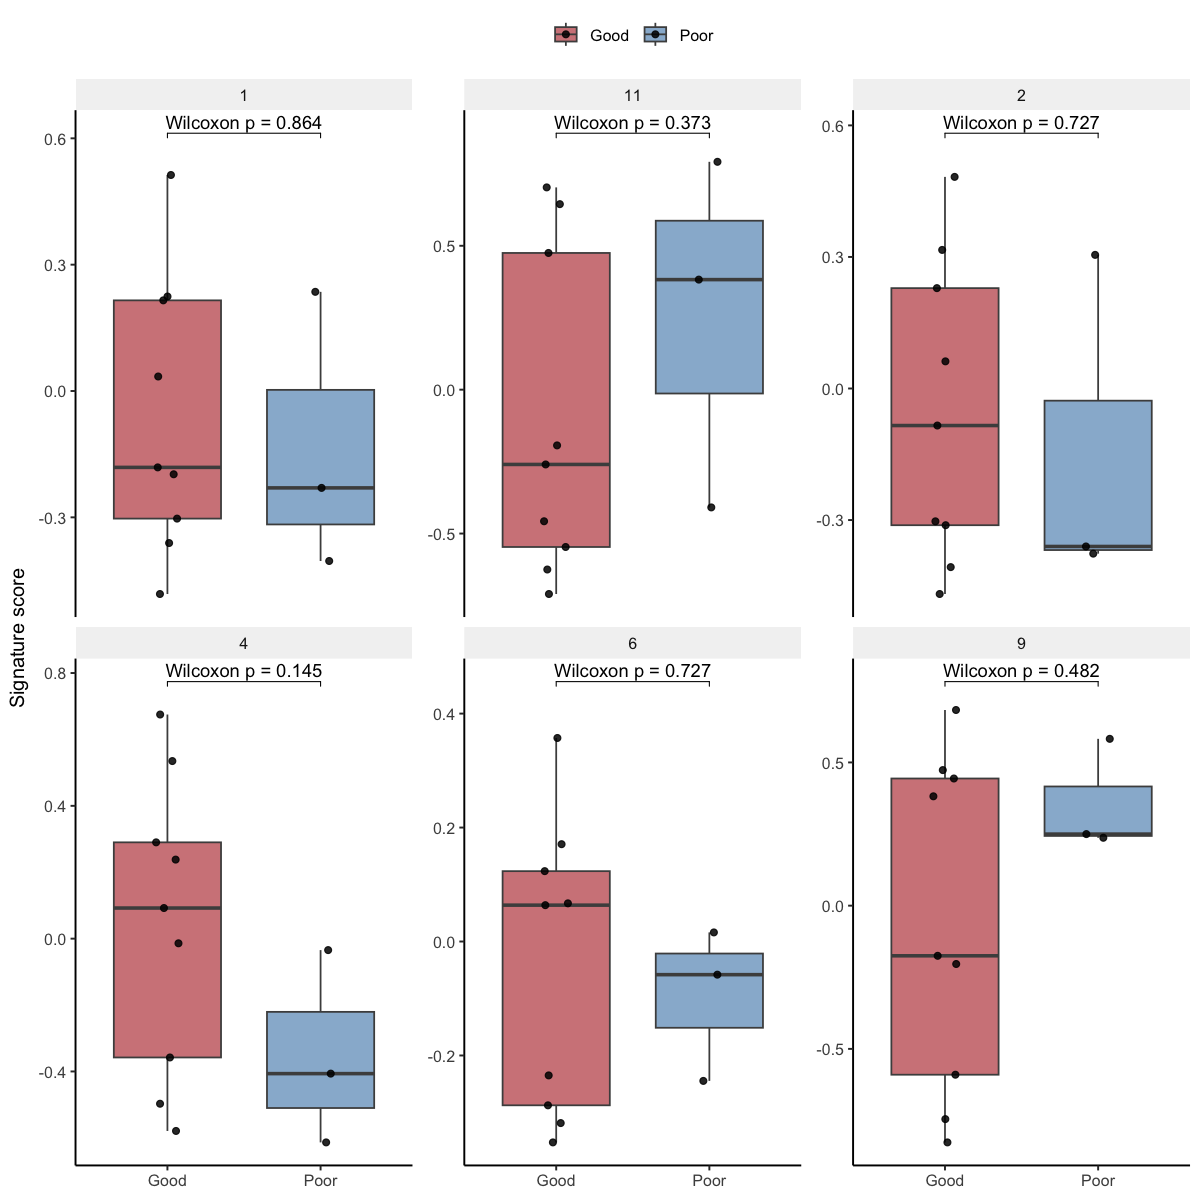

In [6]:
options(repr.plot.height=10,repr.plot.width=10)

# ---------- 2) Good/Poor groups ----------
poor_samples <- sample_metadata$sample[sample_metadata$response_group == "Poor"]
df_long <- df_long %>%
  mutate(group = if_else(sample %in% poor_samples, "Poor", "Good"),
         group = factor(group, levels = c("Good","Poor")))

df_keep <- df_long %>%
  filter(signature %in% c("1", "2","11","6","9","4"))


# ---------- 3) Per-signature Wilcoxon tests (raw p shown on plot) ----------
stats <- df_keep %>%
  group_by(signature) %>%
  wilcox_test(score ~ group, detailed = TRUE) %>%
  # Add positions for ggpubr labels (per facet)
  add_xy_position(x = "group", dodge = 0.1) %>%
  # Nicely formatted "Wilcoxon p = ..." labels
  mutate(label = sprintf("Wilcoxon p = %.3g", p))

# ---------- 4) Boxplots with colors similar to your figure ----------
COLS <- c(Good = "firebrick",  # soft green
          Poor = "steelblue")  # brick red

p <- ggplot(df_keep, aes(group, score, fill = group)) +
  geom_boxplot(width = 0.7, alpha = 0.6, outlier.shape = NA, color = "grey30") +
  geom_jitter(width = 0.08, size = 1.6, alpha = 0.85) +
  facet_wrap(~ signature, scales = "free_y") +
  ggpubr::stat_pvalue_manual(
    stats,
    inherit.aes = FALSE,
    label = "label",          # shows "Wilcoxon p = ..."
    hide.ns = FALSE,          # show all p-values
    tip.length = 0.01
  ) +
  scale_fill_manual(values = COLS) +
  labs(x = NULL, y = "Signature score", fill = NULL) +
  theme_classic(base_size = 12) +
  theme(
    strip.background = element_rect(fill = "grey95", colour = NA),
    panel.grid.minor = element_blank(),
    legend.position = "top"
  )

print(p)


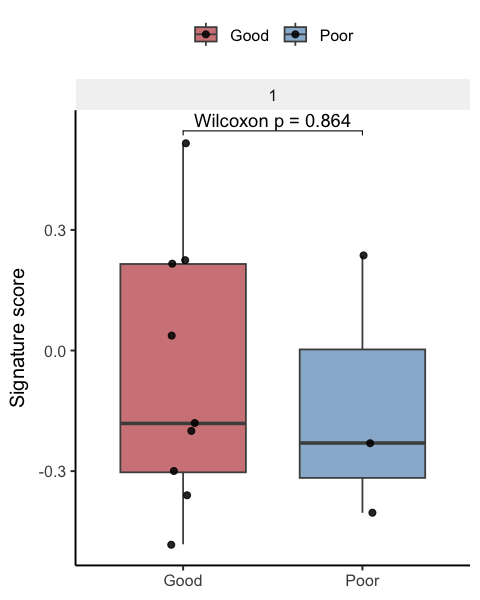

In [7]:
options(repr.plot.height=5,repr.plot.width=4)

# ---------- 2) Good/Poor groups ----------
poor_samples <- sample_metadata$sample[sample_metadata$response_group == "Poor"]
df_long <- df_long %>%
  mutate(group = if_else(sample %in% poor_samples, "Poor", "Good"),
         group = factor(group, levels = c("Good","Poor")))

df_keep <- df_long %>%
  filter(signature %in% c("1"))


# ---------- 3) Per-signature Wilcoxon tests (raw p shown on plot) ----------
stats <- df_keep %>%
  group_by(signature) %>%
  wilcox_test(score ~ group, detailed = TRUE) %>%
  # Add positions for ggpubr labels (per facet)
  add_xy_position(x = "group", dodge = 0.1) %>%
  # Nicely formatted "Wilcoxon p = ..." labels
  mutate(label = sprintf("Wilcoxon p = %.3g", p))

# ---------- 4) Boxplots with colors similar to your figure ----------
COLS <- c(Good = "firebrick",  # soft green
          Poor = "steelblue")  # brick red

p <- ggplot(df_keep, aes(group, score, fill = group)) +
  geom_boxplot(width = 0.7, alpha = 0.6, outlier.shape = NA, color = "grey30") +
  geom_jitter(width = 0.08, size = 1.6, alpha = 0.85) +
  facet_wrap(~ signature, scales = "free_y") +
  ggpubr::stat_pvalue_manual(
    stats,
    inherit.aes = FALSE,
    label = "label",          # shows "Wilcoxon p = ..."
    hide.ns = FALSE,          # show all p-values
    tip.length = 0.01
  ) +
  scale_fill_manual(values = COLS) +
  labs(x = NULL, y = "Signature score", fill = NULL) +
  theme_classic(base_size = 12) +
  theme(
    strip.background = element_rect(fill = "grey95", colour = NA),
    panel.grid.minor = element_blank(),
    legend.position = "top"
  )

print(p)

response_plot_original_style <- p


## 3. Statistical modeling and clinical associations


In [8]:
# Save a vector PDF using the native device (Cairo/X11 is unavailable locally).
ggsave(
  filename = "signature1_boxplot.pdf",
  plot     = p,
  device   = grDevices::pdf,
  useDingbats = FALSE,
  width    = 4,
  height   = 5,
  units    = "in"
)


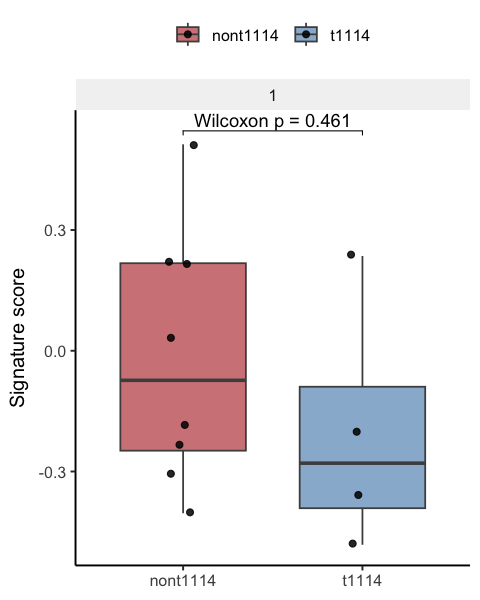

In [9]:
options(repr.plot.height=5,repr.plot.width=4)

# ---------- 2) nont1114/t1114 groups ----------
t1114_samples <- sample_metadata$sample[sample_metadata$cytogenetic_group == "t1114"]
df_long <- df_long %>%
  mutate(group = if_else(sample %in% t1114_samples, "t1114", "nont1114"),
         group = factor(group, levels = c("nont1114","t1114")))

df_keep <- df_long %>%
  filter(signature %in% c("1"))


# ---------- 3) Per-signature Wilcoxon tests (raw p shown on plot) ----------
stats <- df_keep %>%
  group_by(signature) %>%
  wilcox_test(score ~ group, detailed = TRUE) %>%
  # Add positions for ggpubr labels (per facet)
  add_xy_position(x = "group", dodge = 0.1) %>%
  # Nicely formatted "Wilcoxon p = ..." labels
  mutate(label = sprintf("Wilcoxon p = %.3g", p))

# ---------- 4) Boxplots with colors similar to your figure ----------
COLS <- c(nont1114 = "firebrick",  # soft green
          t1114 = "steelblue")  # brick red

p <- ggplot(df_keep, aes(group, score, fill = group)) +
  geom_boxplot(width = 0.7, alpha = 0.6, outlier.shape = NA, color = "grey30") +
  geom_jitter(width = 0.08, size = 1.6, alpha = 0.85) +
  facet_wrap(~ signature, scales = "free_y") +
  ggpubr::stat_pvalue_manual(
    stats,
    inherit.aes = FALSE,
    label = "label",          # shows "Wilcoxon p = ..."
    hide.ns = FALSE,          # show all p-values
    tip.length = 0.01
  ) +
  scale_fill_manual(values = COLS) +
  labs(x = NULL, y = "Signature score", fill = NULL) +
  theme_classic(base_size = 12) +
  theme(
    strip.background = element_rect(fill = "grey95", colour = NA),
    panel.grid.minor = element_blank(),
    legend.position = "top"
  )

print(p)

cytogenetic_plot_original_style <- p


In [10]:
# Save a vector PDF using the native device (Cairo/X11 is unavailable locally).
ggsave(
  filename = "signature1_boxplot_1114.pdf",
  plot     = p,
  device   = grDevices::pdf,
  useDingbats = FALSE,
  width    = 4,
  height   = 5,
  units    = "in"
)


## 4. nont1114/t1114 groups


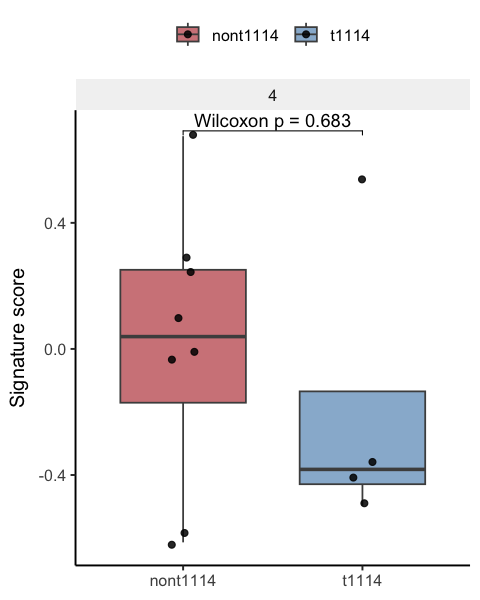

In [11]:
options(repr.plot.height=5,repr.plot.width=4)

# ---------- 2) nont1114/t1114 groups ----------
t1114_samples <- sample_metadata$sample[sample_metadata$cytogenetic_group == "t1114"]
df_long <- df_long %>%
  mutate(group = if_else(sample %in% t1114_samples, "t1114", "nont1114"),
         group = factor(group, levels = c("nont1114","t1114")))

df_keep <- df_long %>%
  filter(signature %in% c("4"))


# ---------- 3) Per-signature Wilcoxon tests (raw p shown on plot) ----------
stats <- df_keep %>%
  group_by(signature) %>%
  wilcox_test(score ~ group, detailed = TRUE) %>%
  # Add positions for ggpubr labels (per facet)
  add_xy_position(x = "group", dodge = 0.1) %>%
  # Nicely formatted "Wilcoxon p = ..." labels
  mutate(label = sprintf("Wilcoxon p = %.3g", p))

# ---------- 4) Boxplots with colors similar to your figure ----------
COLS <- c(nont1114 = "firebrick",  # soft green
          t1114 = "steelblue")  # brick red

p <- ggplot(df_keep, aes(group, score, fill = group)) +
  geom_boxplot(width = 0.7, alpha = 0.6, outlier.shape = NA, color = "grey30") +
  geom_jitter(width = 0.08, size = 1.6, alpha = 0.85) +
  facet_wrap(~ signature, scales = "free_y") +
  ggpubr::stat_pvalue_manual(
    stats,
    inherit.aes = FALSE,
    label = "label",          # shows "Wilcoxon p = ..."
    hide.ns = FALSE,          # show all p-values
    tip.length = 0.01
  ) +
  scale_fill_manual(values = COLS) +
  labs(x = NULL, y = "Signature score", fill = NULL) +
  theme_classic(base_size = 12) +
  theme(
    strip.background = element_rect(fill = "grey95", colour = NA),
    panel.grid.minor = element_blank(),
    legend.position = "top"
  )

print(p)


## Replacement Supplementary Figure 4c PDFs and run provenance


         comparison   group1 group2 n1 n2  W   p_value
1 cytogenetic_group nont1114  t1114  8  4 21 0.4606061
2    response_group     Good   Poor  9  3 15 0.8636364
                        method alternative
1 Wilcoxon rank sum exact test   two.sided
2 Wilcoxon rank sum exact test   two.sided


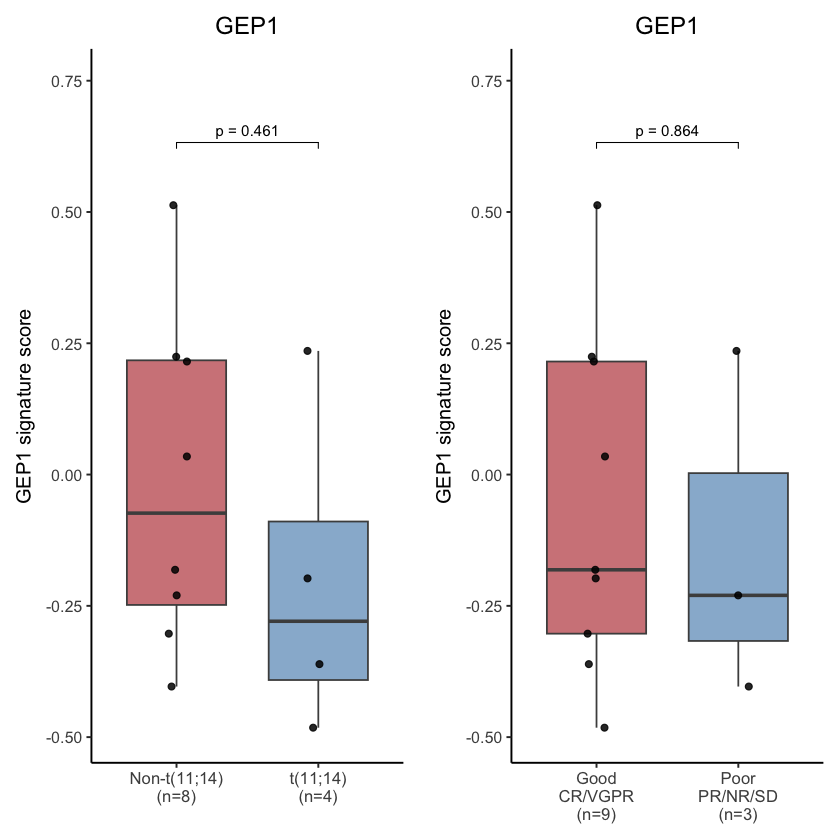

In [4]:
# Save sample-level analysis data, exact unrounded tests, and replacement vector PDFs.
plot_data <- data.frame(sample=colnames(scores), score=as.numeric(scores["1",]),
                        stringsAsFactors=FALSE) %>%
  left_join(sample_metadata, by="sample")
stopifnot(nrow(plot_data)==12L, all(is.finite(plot_data$score)))
write.table(plot_data, "GEP1_sample_scores.tsv", sep="\t", quote=FALSE, row.names=FALSE)

make_publication_plot <- function(data, variable, group_levels, axis_labels, seed) {
  data$group <- factor(data[[variable]], levels=group_levels)
  test <- wilcox.test(score ~ group, data=data, alternative="two.sided",
                      paired=FALSE, exact=NULL, correct=TRUE)
  bounds <- range(data$score)
  span <- diff(bounds)
  annotation <- data.frame(group1=group_levels[1], group2=group_levels[2],
                           y.position=bounds[2]+span*0.12,
                           label=sprintf("p = %.3g", test$p.value))
  p <- ggplot(data, aes(group, score, fill=group)) +
    geom_boxplot(width=0.7, alpha=0.6, outlier.shape=NA, color="grey30") +
    geom_point(position=position_jitter(width=0.08, height=0, seed=seed),
               size=1.6, alpha=0.85) +
    ggpubr::stat_pvalue_manual(annotation, label="label", hide.ns=FALSE, inherit.aes=FALSE,
                               tip.length=0.01, bracket.size=0.3, size=3.2) +
    scale_fill_manual(values=setNames(c("firebrick","steelblue"),group_levels)) +
    scale_x_discrete(labels=axis_labels) +
    scale_y_continuous(expand=expansion(mult=c(0.06,0.16))) +
    labs(x=NULL, y="GEP1 signature score", title="GEP1") +
    theme_classic(base_size=12) +
    theme(legend.position="none", plot.title=element_text(hjust=0.5),
          axis.text.x=element_text(size=10), plot.margin=margin(10,10,10,10))
  list(plot=p, test=data.frame(comparison=variable, group1=group_levels[1],
       group2=group_levels[2], n1=sum(data$group==group_levels[1]),
       n2=sum(data$group==group_levels[2]), W=unname(test$statistic),
       p_value=test$p.value, method=test$method, alternative=test$alternative))
}

cyto <- make_publication_plot(plot_data, "cytogenetic_group",
          c("nont1114","t1114"),
          c(nont1114="Non-t(11;14)\n(n=8)", t1114="t(11;14)\n(n=4)"),20261025)
response <- make_publication_plot(plot_data, "response_group", c("Good","Poor"),
          c(Good="Good\nCR/VGPR\n(n=9)", Poor="Poor\nPR/NR/SD\n(n=3)"),20261026)
tests <- bind_rows(cyto$test,response$test)
write.table(tests,"GEP1_Wilcoxon_tests.tsv",sep="\t",quote=FALSE,row.names=FALSE)

# Confirm plotting tests agree with the original rstatix procedure.
for (i in seq_len(nrow(tests))) {
  d <- plot_data
  d$group <- factor(d[[tests$comparison[i]]],levels=c(tests$group1[i],tests$group2[i]))
  rt <- rstatix::wilcox_test(d,score~group,detailed=TRUE)
  stopifnot(abs(rt$p-tests$p_value[i]) < 0.00051)
}
ggsave("Supplementary_Fig4c_cytogenetics.pdf",cyto$plot,device=grDevices::pdf,useDingbats=FALSE,width=3.1,height=4,units="in")
ggsave("Supplementary_Fig4c_response.pdf",response$plot,device=grDevices::pdf,useDingbats=FALSE,width=3.1,height=4,units="in")
combined <- ggpubr::ggarrange(cyto$plot,response$plot,ncol=2,nrow=1,align="hv")
ggsave("Supplementary_Fig4c_replacement.pdf",combined,device=grDevices::pdf,useDingbats=FALSE,width=6.2,height=4,units="in")
stopifnot(all(file.exists(c("Supplementary_Fig4c_cytogenetics.pdf",
                           "Supplementary_Fig4c_response.pdf",
                           "Supplementary_Fig4c_replacement.pdf"))))
print(combined)
print(tests)
writeLines(capture.output(sessionInfo()),"audit/sessionInfo.txt")
writeLines(capture.output(AnnotationDbi::metadata(org.Hs.eg.db)),"audit/org.Hs.eg.db_metadata.txt")
